# ML-10 — Content Action Playbook

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

In [1]:
"""The queue. Every page gets a score from my w05 logistic regression, but scored OUT-OF-FOLD (5-fold grouped by client), so each page is scored by a model that never saw its client. Thats the closest thing I have to "running it on a new client".
Big lesson from trying a single global list first: the top 100 of one pooled list were ALL from one client. Editors work per client, so the queue is ranked inside each client, and the review order goes round-robin (every client's #1, then every client's #2...).
Each row carries reason codes in plain words, a suggested action, and a confidence band. The bands are checked against what actually happened (hindsight), not just asserted."""

import sys
sys.path.insert(0, "../scripts")
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lane_features as lf
import lane_baseline as lb
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold

raw = lf.load_raw()
df = lf.build_features(raw)
X = lf.feature_matrix(df)
y = df["is_declining_label"].to_numpy()

folds = list(GroupKFold(n_splits=5).split(X, y, groups=df["client_id"]))
df["decline_risk"] = 0.0
for a, b in folds:
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X.iloc[a], y[a])
    df.loc[df.index[b], "decline_risk"] = model.predict_proba(X.iloc[b])[:, 1]
df["rule_points"] = lb.baseline_points(df)
base_score = lb.baseline_score(df).to_numpy()
fold_p50 = pd.DataFrame([{"model": lf.precision_at_k(y[b], df["decline_risk"].to_numpy()[b], 50),
                          "rule": lf.precision_at_k(y[b], base_score[b], 50), "base_rate": y[b].mean()} for a, b in folds])
print(f"P@50 per held-out fold, model: {fold_p50['model'].round(2).tolist()} | rule: {fold_p50['rule'].round(2).tolist()} (same as w06)")

# reason codes: the frozen rule's codes + two the model taught me to look at (w05 error analysis)
codes = lb.reason_codes(df)
codes = codes.where(~((df["impressions_prev_30d"] >= 100) & (df["ctr_prev30"] < 0.1)), codes + "|impressions_without_clicks")
codes = codes.where(~(df["content_age_days"] < 180), codes + "|young_page")
df["reason_codes"] = codes.str.replace("general_review|", "", regex=False)

plain_words = {
    "already_sliding": "lost 20%+ impressions going into the last month",
    "impressions_without_clicks": "shows up in search but almost nobody clicks",
    "young_page": "under 6 months old, young pages fall back more often",
    "visible_before": "had real search visibility",
    "recent_spike": "just spiked, could fall back",
    "still_settling": "under a year old",
    "low_volume": "small numbers, a few impressions swing it",
    "no_prior_traffic": "no impressions in days 31-60, nothing to lose",
}
order = ["no_prior_traffic", "already_sliding", "impressions_without_clicks", "recent_spike", "young_page", "low_volume", "visible_before", "still_settling"]
def why(code_str):
    present = [c for c in order if c in code_str.split("|")]
    return "; ".join(plain_words[c] for c in present[:2]) if present else "no specific flag, model score only"
df["why"] = df["reason_codes"].map(why)

has = lambda name: df["reason_codes"].str.contains(name)
df["suggested_action"] = np.select(
    [has("no_prior_traffic"),
     has("already_sliding") & has("visible_before"),
     has("impressions_without_clicks"),
     has("recent_spike")],
    ["no_action", "refresh_review", "snippet_and_intent_review", "watch_spike"],
    "monitor",
)
df["confidence"] = np.select(
    [(df["decline_risk"] >= 0.80) & (df["rule_points"] >= 3), (df["decline_risk"] >= 0.70) | (df["rule_points"] == 4), df["decline_risk"] >= 0.50],
    ["high", "medium", "low"], "none",
)
df.loc[df["suggested_action"] == "no_action", "confidence"] = "none"

# rank inside each client, then round-robin across clients
df["client_rank"] = df.groupby("client_id")["decline_risk"].rank(ascending=False, method="first").astype(int)
queue = df.sort_values(["client_rank", "decline_risk"], ascending=[True, False]).reset_index(drop=True)
queue.insert(0, "review_order", np.arange(1, len(queue) + 1))
client_index = {c: f"client_{i:02d}" for i, c in enumerate(df.groupby("client_id").size().sort_values(ascending=False).index, start=1)}
queue["client"] = queue["client_id"].map(client_index)

cols = ["review_order", "client", "client_rank", "decline_risk", "suggested_action", "confidence", "why"]
with pd.option_context("display.max_colwidth", None, "display.width", 220):
    display(queue[cols].head(12).round(3))

# are the confidence bands honest? (hindsight, out-of-fold)
bands = df.groupby("confidence")["is_declining_label"].agg(declined="mean", pages="size").reindex(["high", "medium", "low", "none"]).round(3)
print(f"confidence bands vs what actually happened (base rate {y.mean():.0%}):")
display(bands)

# does ranking inside a client help? top 10 per client vs that client's own base rate
lift = []
for cid, g in df.groupby("client_id"):
    if len(g) >= 50 and g["is_declining_label"].nunique() == 2:
        top10 = g.nlargest(10, "decline_risk")["is_declining_label"].mean()
        rule10 = g.assign(r=lb.baseline_score(g)).nlargest(10, "r")["is_declining_label"].mean()
        lift.append({"client": client_index[cid], "pages": len(g), "client base rate": g["is_declining_label"].mean(), "model top 10": top10, "rule top 10": rule10})
lift = pd.DataFrame(lift).set_index("client").round(2)
print(f"inside each client with 50+ pages ({len(lift)} clients): model top-10 hit rate {lift['model top 10'].mean():.0%} vs rule top-10 {lift['rule top 10'].mean():.0%} vs their own base rate {lift['client base rate'].mean():.0%} (averages over clients)")
print(f"model top 10 beats the client's base rate in {(lift['model top 10'] > lift['client base rate']).sum()} of {len(lift)} clients, beats the rule's top 10 in {(lift['model top 10'] > lift['rule top 10']).sum()}, ties {(lift['model top 10'] == lift['rule top 10']).sum()}")

P@50 per held-out fold, model: [0.7, 0.82, 0.66, 0.8, 0.98] | rule: [0.74, 0.66, 0.5, 0.7, 0.86] (same as w06)


,review_order,client,client_rank,decline_risk,suggested_action,confidence,why
0,1,client_02,1,0.968,refresh_review,high,lost 20%+ impressions going into the last month; shows up in search but almost nobody clicks
1,2,client_15,1,0.886,refresh_review,high,lost 20%+ impressions going into the last month; shows up in search but almost nobody clicks
2,3,client_09,1,0.881,snippet_and_intent_review,medium,"shows up in search but almost nobody clicks; under 6 months old, young pages fall back more often"
3,4,client_05,1,0.880,snippet_and_intent_review,medium,"shows up in search but almost nobody clicks; under 6 months old, young pages fall back more often"
4,5,client_20,1,0.879,snippet_and_intent_review,medium,"shows up in search but almost nobody clicks; under 6 months old, young pages fall back more often"
5,6,client_01,1,0.875,snippet_and_intent_review,medium,"shows up in search but almost nobody clicks; under 6 months old, young pages fall back more often"
6,7,client_18,1,0.870,snippet_and_intent_review,medium,"shows up in search but almost nobody clicks; under 6 months old, young pages fall back more often"
7,8,client_03,1,0.870,refresh_review,high,lost 20%+ impressions going into the last month; shows up in search but almost nobody clicks
8,9,client_10,1,0.869,refresh_review,high,lost 20%+ impressions going into the last month; shows up in search but almost nobody clicks
9,10,client_12,1,0.856,snippet_and_intent_review,medium,"shows up in search but almost nobody clicks; under 6 months old, young pages fall back more often"


confidence bands vs what actually happened (base rate 54%):


,declined,pages
confidence,,
high,0.759,1220
medium,0.698,11703
low,0.532,10667
none,0.233,6410


inside each client with 50+ pages (24 clients): model top-10 hit rate 75% vs rule top-10 65% vs their own base rate 53% (averages over clients)
model top 10 beats the client's base rate in 22 of 24 clients, beats the rule's top 10 in 13, ties 7


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

In [2]:
n_clients = df["client_id"].nunique()
print(f"""INTENDED USE (a one-page card for the queue)
- who: content reviewers / editors working through a client's pages.
- for what: deciding the ORDER of manual review. "start with these 10 pages for this client, and here is why each one is on the list".
- what it is: a logistic regression on 16 numeric + 3 categorical features, all known before the last 30 days (w03), ranking pages by risk of losing 20%+ of search impressions in the next 30 days. the frozen 0-4 point rule (w04) stays next to it as the readable fallback.
- how good, measured honestly: 5-fold grouped by client, P@50 {fold_p50['model'].mean():.2f} +- {fold_p50['model'].std():.2f} vs {fold_p50['rule'].mean():.2f} for the rule and a {y.mean():.0%} base rate. inside a client, its top 10 averages {lift['model top 10'].mean():.0%} declined vs {lift['client base rate'].mean():.0%} base rate.

WHERE IT STOPS BEING VALID
- outside this snapshot: one 90 day window from {n_clients} pseudonymized clients. nothing checked it on a later month, so its a ranking of this period, not a tested forecast.
- pages it never saw the like of: every page here is 90+ days old with some impressions AND sessions. brand new pages, zero-traffic pages and pages with no GA4 are out of scope.
- after a site-wide event: migrations, tracking changes, seasonality hit a whole client at once. the queue will read that as "every page is declining" (w04 showed misses clustering by client).
- tiny pages: below ~100 impressions a month a couple of impressions flip the label, the model ranks them low on purpose. dont read their score.
- the label is impressions only (GSC). a page can keep impressions and lose clicks, or the reverse. it says nothing about revenue, rankings or content quality.
- causality: nothing here shows that refreshing a page stops the decline. its decision-support for where to look, the refresh itself is an editor's call.""")

INTENDED USE (a one-page card for the queue)
- who: content reviewers / editors working through a client's pages.
- for what: deciding the ORDER of manual review. "start with these 10 pages for this client, and here is why each one is on the list".
- what it is: a logistic regression on 16 numeric + 3 categorical features, all known before the last 30 days (w03), ranking pages by risk of losing 20%+ of search impressions in the next 30 days. the frozen 0-4 point rule (w04) stays next to it as the readable fallback.
- how good, measured honestly: 5-fold grouped by client, P@50 0.79 +- 0.12 vs 0.69 for the rule and a 54% base rate. inside a client, its top 10 averages 75% declined vs 53% base rate.

WHERE IT STOPS BEING VALID
- outside this snapshot: one 90 day window from 32 pseudonymized clients. nothing checked it on a later month, so its a ranking of this period, not a tested forecast.
- pages it never saw the like of: every page here is 90+ days old with some impressions AND session

## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

In [3]:
print("""BEFORE ACTING, a human checks (in this order):
1. the client first. if a big share of the client's top 10 are 'declining', check for a site-wide cause (migration, tracking/GA4 change, seasonality, a manual action) before touching any page.
2. the keyword. is demand for the target keyword itself falling (seasonal or trend)? then the page isnt the problem.
3. the page in search. who is ranking now, did the intent of the results change, is the snippet still a fit?
4. the page itself. outdated facts, broken parts, thin sections. only then decide refresh / snippet fix / leave it.
5. write down what was done and the date, so the next cycle can compare against untouched pages (thats how we eventually learn if refreshes help).

NO-GO LIST (never automated off this score):
- publishing, rewriting or AI-regenerating content without a human editor reading it.
- deleting, noindexing, redirecting or merging pages. a high decline risk is not a reason to remove a page.
- anything client-facing that says "this page WILL drop" or "refreshing WILL fix it". the evidence is a ranking, not a forecast or a causal effect.
- comparing or ranking clients against each other with this score (the base rates differ a lot between clients and the model wasnt built for it).
- using the score for people decisions (editor performance etc).
- treating the confidence band as a probability promise: 'high' meant about 3 in 4 declined in this snapshot, not a guarantee.""")

BEFORE ACTING, a human checks (in this order):
1. the client first. if a big share of the client's top 10 are 'declining', check for a site-wide cause (migration, tracking/GA4 change, seasonality, a manual action) before touching any page.
2. the keyword. is demand for the target keyword itself falling (seasonal or trend)? then the page isnt the problem.
3. the page in search. who is ranking now, did the intent of the results change, is the snippet still a fit?
4. the page itself. outdated facts, broken parts, thin sections. only then decide refresh / snippet fix / leave it.
5. write down what was done and the date, so the next cycle can compare against untouched pages (thats how we eventually learn if refreshes help).

NO-GO LIST (never automated off this score):
- publishing, rewriting or AI-regenerating content without a human editor reading it.
- deleting, noindexing, redirecting or merging pages. a high decline risk is not a reason to remove a page.
- anything client-facing that s

## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

In [4]:
"""What would tell me the queue went stale. Two kinds of check: input drift I can see right away (before labels exist), and outcome checks once the next 30 days are in.
For input drift I use PSI (population stability index) on the key features against this snapshot. Below I run it on a pretend "new month": the clients split into two halves, half B treated as new data vs half A, just to show what the check prints."""

def psi(ref, new, bins=10):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    r = np.histogram(ref, edges)[0] / len(ref)
    n = np.histogram(new, edges)[0] / len(new)
    r, n = np.clip(r, 1e-4, None), np.clip(n, 1e-4, None)
    return float(np.sum((n - r) * np.log(n / r)))

def drift_report(ref, new):
    key = ["log_impr_prev30", "log_impr_d61_90", "impr_momentum_prior", "ctr_prev30", "age_at_prediction", "word_count"]
    rows = {f: psi(ref[f].to_numpy(), new[f].to_numpy()) for f in key}
    rows["share with no prior traffic (pts)"] = 100 * (new["prev30_empty"].mean() - ref["prev30_empty"].mean())
    rows["share of keyword articles (pts)"] = 100 * ((new["content_type"] == "keyword article").mean() - (ref["content_type"] == "keyword article").mean())
    return pd.Series(rows).round(3)

halves = sorted(df["client_id"].unique())
half_a = df[df["client_id"].isin(halves[0::2])]
half_b = df[df["client_id"].isin(halves[1::2])]
report = drift_report(half_a, half_b)
display(report.to_frame("pretend new month vs snapshot"))
flagged = [f for f in report.index if "(pts)" not in f and report[f] > 0.2]
print("features over the PSI 0.2 line:", flagged if flagged else "none")
print(f"word_count is the loud one because word counts were measured for {half_a['has_word_count'].mean():.0%} of half A's pages but {half_b['has_word_count'].mean():.0%} of half B's, "
      "the missing ones are 0 + a flag. thats a measurement difference between clients, not longer or shorter pages, and its the kind of thing this check is for.")
print("(two different sets of clients already drift on some features, which is exactly why a new client should be treated as 'new data' and checked first)")

print("""
RETRAIN / STOP TRIGGERS
- input drift: PSI > 0.2 on any key feature, or the share of no-prior-traffic pages moves 5+ points -> look before using the queue. > 0.25 on the traffic features -> retrain.
- outcome check every cycle, once the 30 days are in: top-10-per-client hit rate vs the rule's top 10 on the same pages. model below the rule for 2 cycles in a row -> switch the queue to the rule and retrain.
- base rate moves 10+ points (e.g. a sector-wide drop) -> the 20% threshold and the confidence bands need rechecking.
- more than a quarter of the pages come from clients the model never trained on -> treat the run as new-client mode, rule first, model second, until one outcome cycle is in.
- anything in the label changes (the 20% cut, how impressions are counted, GSC changes) -> rebuild, the old scores dont mean the same thing.
- editors report the same 'wrong' reason twice (e.g. seasonal pages keep coming up) -> add that as a reason code or exclusion before the next run.""")

,pretend new month vs snapshot
log_impr_prev30,0.140
log_impr_d61_90,0.116
impr_momentum_prior,0.148
ctr_prev30,0.051
age_at_prediction,0.106
word_count,1.188
share with no prior traffic (pts),-3.102
share of keyword articles (pts),0.515


features over the PSI 0.2 line: ['word_count']
word_count is the loud one because word counts were measured for 67% of half A's pages but 87% of half B's, the missing ones are 0 + a flag. thats a measurement difference between clients, not longer or shorter pages, and its the kind of thing this check is for.
(two different sets of clients already drift on some features, which is exactly why a new client should be treated as 'new data' and checked first)

RETRAIN / STOP TRIGGERS
- input drift: PSI > 0.2 on any key feature, or the share of no-prior-traffic pages moves 5+ points -> look before using the queue. > 0.25 on the traffic features -> retrain.
- outcome check every cycle, once the 30 days are in: top-10-per-client hit rate vs the rule's top 10 on the same pages. model below the rule for 2 cycles in a row -> switch the queue to the rule and retrain.
- base rate moves 10+ points (e.g. a sector-wide drop) -> the 20% threshold and the confidence bands need rechecking.
- more than a q

## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

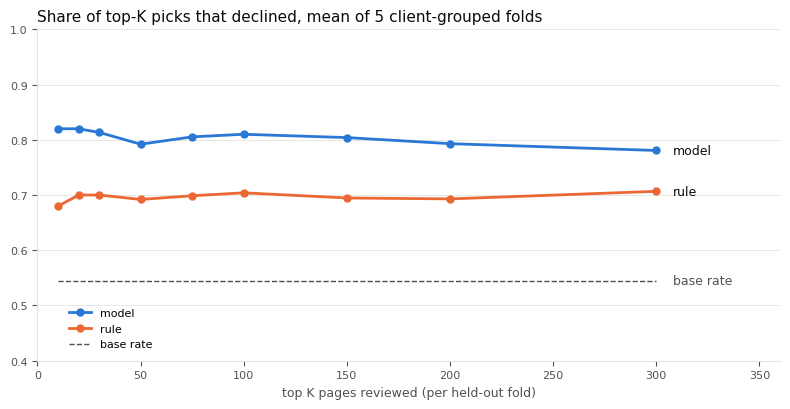

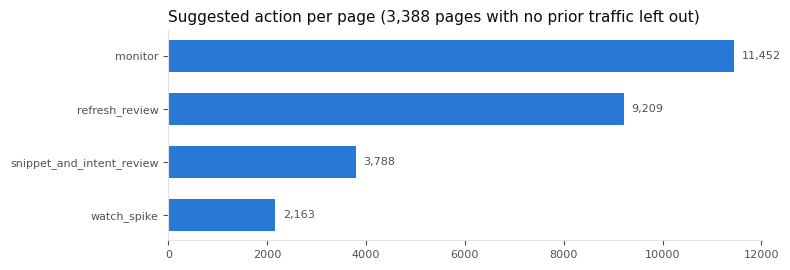

wrote ..\outputs\action_queue.csv (6,219 KB)
wrote ..\outputs\playbook_summary.json (2 KB)
wrote ..\outputs\precision_at_k_table.md (0 KB)
wrote ..\figures\w07_precision_at_k.png (40 KB)
wrote ..\figures\w07_action_mix.png (28 KB)


In [5]:
"""Exports for the paper. The queue CSV stays local (work/**/*.csv is gitignored, it has row-level pseudonymized ids). What goes in the repo: aggregate numbers as json + a markdown table, and the figures."""

out_dir, fig_dir = Path("../outputs"), Path("../figures")
out_dir.mkdir(exist_ok=True)
fig_dir.mkdir(exist_ok=True)
INK, MUTED, GRID, BLUE, ORANGE = "#0b0b0b", "#52514e", "#e4e3df", "#2a78d6", "#eb6834"

export_cols = ["review_order", "client", "client_rank", "content_id", "decline_risk", "rule_points", "suggested_action", "confidence", "reason_codes", "why"]
queue[export_cols].to_csv(out_dir / "action_queue.csv", index=False)

# precision@K per fold, model vs rule (same rows), mean over the 5 folds
ks = [10, 20, 30, 50, 75, 100, 150, 200, 300]
curves = {"model": [], "rule": [], "base rate": []}
for a, b in folds:
    curves["model"].append([lf.precision_at_k(y[b], df["decline_risk"].to_numpy()[b], k) for k in ks])
    curves["rule"].append([lf.precision_at_k(y[b], base_score[b], k) for k in ks])
    curves["base rate"].append([y[b].mean()] * len(ks))
curve = {name: np.mean(v, axis=0) for name, v in curves.items()}

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(ks, curve["model"], color=BLUE, linewidth=2, marker="o", markersize=5)
ax.plot(ks, curve["rule"], color=ORANGE, linewidth=2, marker="o", markersize=5)
ax.plot(ks, curve["base rate"], color=MUTED, linewidth=1, linestyle="--")
ax.text(ks[-1] + 8, curve["model"][-1], "model", color=INK, va="center", fontsize=9)
ax.text(ks[-1] + 8, curve["rule"][-1], "rule", color=INK, va="center", fontsize=9)
ax.text(ks[-1] + 8, curve["base rate"][-1], "base rate", color=MUTED, va="center", fontsize=9)
ax.set_xlim(0, ks[-1] + 60)
ax.set_ylim(0.4, 1.0)
ax.set_xlabel("top K pages reviewed (per held-out fold)", color=MUTED, fontsize=9)
ax.set_title("Share of top-K picks that declined, mean of 5 client-grouped folds", loc="left", fontsize=11, color=INK)
ax.grid(axis="y", color=GRID, linewidth=0.6)
ax.tick_params(colors=MUTED, labelsize=8)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color(GRID)
fig.legend(["model", "rule", "base rate"], loc="lower left", bbox_to_anchor=(0.08, 0.13), frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(fig_dir / "w07_precision_at_k.png", dpi=130)
plt.show()

mix = queue[queue["suggested_action"] != "no_action"]["suggested_action"].value_counts()
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(mix.index[::-1], mix.values[::-1], color=BLUE, height=0.6)
for i, v in enumerate(mix.values[::-1]):
    ax.text(v + 150, i, f"{v:,}", va="center", fontsize=8, color=MUTED)
ax.set_title(f"Suggested action per page ({(queue['suggested_action'] == 'no_action').sum():,} pages with no prior traffic left out)", loc="left", fontsize=11, color=INK)
ax.tick_params(colors=MUTED, labelsize=8)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color(GRID)
fig.tight_layout()
fig.savefig(fig_dir / "w07_action_mix.png", dpi=130)
plt.show()

summary = {
    "data": {"pages": int(len(df)), "clients": int(df["client_id"].nunique()), "base_rate": round(float(y.mean()), 3),
             "label": "impressions last 30d < 0.8 x previous 30d (trend_direction == down)", "prediction_moment": "day -30, features from days 31-90 + content metadata"},
    "validation": "5-fold GroupKFold by client, logistic regression, seed 42",
    "per_fold_p50": fold_p50.round(3).to_dict(orient="records"),
    "mean_p50": {"model": round(float(fold_p50["model"].mean()), 3), "model_std": round(float(fold_p50["model"].std()), 3), "rule": round(float(fold_p50["rule"].mean()), 3)},
    "precision_at_k_curve": {"k": ks, **{name: [round(float(v), 3) for v in vals] for name, vals in curve.items()}},
    "confidence_bands": {band: {"declined": float(r.declined), "pages": int(r.pages)} for band, r in bands.iterrows()},
    "within_client_top10": {"clients": int(len(lift)), "model": round(float(lift["model top 10"].mean()), 3), "rule": round(float(lift["rule top 10"].mean()), 3), "client_base_rate": round(float(lift["client base rate"].mean()), 3)},
    "action_counts": {k: int(v) for k, v in queue["suggested_action"].value_counts().items()},
}
(out_dir / "playbook_summary.json").write_text(json.dumps(summary, indent=2))

table = pd.DataFrame({"K": ks, "model": curve["model"], "rule": curve["rule"], "base rate": curve["base rate"]}).round(3)
md = "| K | model | rule | base rate |\n|---:|---:|---:|---:|\n" + "\n".join(f"| {r.K} | {r.model:.3f} | {r.rule:.3f} | {r._4:.3f} |" for r in table.itertuples())
(out_dir / "precision_at_k_table.md").write_text("Precision@K, mean of 5 client-grouped folds (logistic regression vs frozen rule)\n\n" + md + "\n")

for p in [out_dir / "action_queue.csv", out_dir / "playbook_summary.json", out_dir / "precision_at_k_table.md", fig_dir / "w07_precision_at_k.png", fig_dir / "w07_action_mix.png"]:
    print(f"wrote {p} ({p.stat().st_size / 1024:,.0f} KB)")

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.